In [ ]:
# ============================================================
# STEP 1 — ISIC 2018 TASK 3 DATASET SETUP
# ============================================================

import os
import torch
import numpy as np
import pandas as pd
import random

print("=" * 40)
print("STEP 1 — ISIC 2018 TASK 3 DATASET SETUP")
print("=" * 40)


# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("\n✓ Random Seed:", SEED)


# ------------------------------------------------------------
# 2. Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("✓ Device:", device)

if torch.cuda.is_available():
    print("✓ GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 3. Search for ISIC Task 3 directories
# ------------------------------------------------------------

print("\nSearching for ISIC 2018 Task 3 folders...")

input_dir = None
groundtruth_dir = None

for root, dirs, files in os.walk("/kaggle/input"):

    for directory in dirs:

        directory_lower = directory.lower()

        # Training Input folder
        if (
            "isic2018" in directory_lower
            and "training_input" in directory_lower
        ):
            input_dir = os.path.join(root, directory)

        # GroundTruth folder
        if (
            "isic2018" in directory_lower
            and "groundtruth" in directory_lower
        ):
            groundtruth_dir = os.path.join(root, directory)


# ------------------------------------------------------------
# 4. Verify paths
# ------------------------------------------------------------

print("\n" + "-" * 60)

print("Training Input Directory:")
print(input_dir)

print("\nTraining GroundTruth Directory:")
print(groundtruth_dir)


if input_dir is None:
    raise FileNotFoundError(
        "ISIC 2018 Task 3 Training Input folder was not found."
    )

if groundtruth_dir is None:
    raise FileNotFoundError(
        "ISIC 2018 Task 3 GroundTruth folder was not found."
    )


# ------------------------------------------------------------
# 5. Count images
# ------------------------------------------------------------

image_files = [
    f for f in os.listdir(input_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("\nNumber of image files found:")
print(len(image_files))


# ------------------------------------------------------------
# 6. Display sample images
# ------------------------------------------------------------

print("\nFirst 10 image files:")

for file in image_files[:10]:
    print("  →", file)


# ------------------------------------------------------------
# 7. GroundTruth files
# ------------------------------------------------------------

print("\nGroundTruth files:")

for file in os.listdir(groundtruth_dir)[:20]:
    print("  →", file)


# ------------------------------------------------------------
# 8. Save paths for later steps
# ------------------------------------------------------------

IMAGE_DIR = input_dir
GROUNDTRUTH_DIR = groundtruth_dir



STEP 1 — ISIC 2018 TASK 3 DATASET SETUP

✓ Random Seed: 42
✓ Device: cuda
✓ GPU: Tesla T4

Searching for ISIC 2018 Task 3 folders...

------------------------------------------------------------
Training Input Directory:
/kaggle/input/datasets/vedant1703/isic2018-task3-trainingdata/ISIC2018_Task3_Training_Input

Training GroundTruth Directory:
/kaggle/input/datasets/vedant1703/isic2018-task3-traininggroundtruth/ISIC2018_Task3_Training_GroundTruth

Number of image files found:
10015

First 10 image files:
  → ISIC_0030912.jpg
  → ISIC_0028933.jpg
  → ISIC_0030585.jpg
  → ISIC_0028394.jpg
  → ISIC_0033697.jpg
  → ISIC_0030062.jpg
  → ISIC_0031213.jpg
  → ISIC_0027799.jpg
  → ISIC_0028100.jpg
  → ISIC_0027960.jpg

GroundTruth files:
  → LICENSE.txt
  → ATTRIBUTION.txt
  → ISIC2018_Task3_Training_GroundTruth.csv


In [ ]:
# ============================================================
# STEP 2 — LABEL CONVERSION + CLASS IMBALANCE ANALYSIS
# ISIC 2018 TASK 3
# ============================================================

import os
import pandas as pd
import numpy as np

print("=" * 40)
print("STEP 2 — LABEL CONVERSION + CLASS IMBALANCE")
print("=" * 40)


# ------------------------------------------------------------
# 1. GroundTruth CSV
# ------------------------------------------------------------

groundtruth_csv = os.path.join(
    GROUNDTRUTH_DIR,
    "ISIC2018_Task3_Training_GroundTruth.csv"
)

print("\nGroundTruth CSV:")
print(groundtruth_csv)


# ------------------------------------------------------------
# 2. Load CSV
# ------------------------------------------------------------

gt_df = pd.read_csv(groundtruth_csv)

print("\nGroundTruth Shape:")
print(gt_df.shape)

print("\nGroundTruth Columns:")
print(gt_df.columns.tolist())


# ------------------------------------------------------------
# 3. ISIC 2018 Task 3 Classes
# ------------------------------------------------------------

class_columns = [
    "MEL",
    "NV",
    "BCC",
    "AKIEC",
    "BKL",
    "DF",
    "VASC"
]

class_names = [
    "Melanoma",
    "Melanocytic Nevus",
    "Basal Cell Carcinoma",
    "Actinic Keratosis",
    "Benign Keratosis",
    "Dermatofibroma",
    "Vascular Lesion"
]


# ------------------------------------------------------------
# 4. Verify GroundTruth Columns
# ------------------------------------------------------------

missing_columns = [
    col for col in class_columns
    if col not in gt_df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing expected class columns: {missing_columns}\n"
        f"Available columns: {gt_df.columns.tolist()}"
    )


print("\n✓ All 7 ISIC class columns found")


# ------------------------------------------------------------
# 5. Convert One-Hot Labels to Integer Labels
# ------------------------------------------------------------

gt_df["label"] = (
    gt_df[class_columns]
    .values
    .argmax(axis=1)
)


# ------------------------------------------------------------
# 6. Create Image + Label DataFrame
# ------------------------------------------------------------

df = gt_df[
    ["image", "label"]
].copy()


# ------------------------------------------------------------
# 7. First 10 Samples
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("LABEL CONVERSION")
print("=" * 60)

print("\nFirst 10 Samples:")

display(df.head(10))


# ------------------------------------------------------------
# 8. Class Mapping
# ------------------------------------------------------------

print("\nClass Mapping:")

for i, name in enumerate(class_names):

    print(
        f"{i} → {name} ({class_columns[i]})"
    )


# ------------------------------------------------------------
# 9. Overall Class Distribution
# ------------------------------------------------------------

class_counts = (
    df["label"]
    .value_counts()
    .sort_index()
)


print("\n" + "=" * 40)
print("ORIGINAL CLASS DISTRIBUTION")
print("=" * 40)

for label in range(7):

    count = class_counts.get(label, 0)

    percentage = (
        count / len(df)
    ) * 100

    print(
        f"{label} → "
        f"{class_names[label]:25s} : "
        f"{count:5d} "
        f"({percentage:6.2f}%)"
    )


# ------------------------------------------------------------
# 10. Total Images
# ------------------------------------------------------------

print("\nTotal Images:")
print(len(df))


# ------------------------------------------------------------
# 11. Imbalance Ratio
# ------------------------------------------------------------

majority_count = class_counts.max()
minority_count = class_counts.min()

majority_class = class_counts.idxmax()
minority_class = class_counts.idxmin()

imbalance_ratio = (
    majority_count / minority_count
)


print("\n" + "=" * 40)
print("CLASS IMBALANCE ANALYSIS")
print("=" * 40)

print(
    f"Majority Class : "
    f"{class_names[majority_class]}"
)

print(
    f"Majority Samples: "
    f"{majority_count}"
)

print(
    f"Minority Class : "
    f"{class_names[minority_class]}"
)

print(
    f"Minority Samples: "
    f"{minority_count}"
)

print(
    f"Imbalance Ratio: "
    f"{imbalance_ratio:.2f}:1"
)


STEP 2 — LABEL CONVERSION + CLASS IMBALANCE

GroundTruth CSV:
/kaggle/input/datasets/vedant1703/isic2018-task3-traininggroundtruth/ISIC2018_Task3_Training_GroundTruth/ISIC2018_Task3_Training_GroundTruth.csv

GroundTruth Shape:
(10015, 8)

GroundTruth Columns:
['image', 'MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']

✓ All 7 ISIC class columns found

LABEL CONVERSION

First 10 Samples:


,image,label
0,ISIC_0024306,1
1,ISIC_0024307,1
2,ISIC_0024308,1
3,ISIC_0024309,1
4,ISIC_0024310,0
5,ISIC_0024311,1
6,ISIC_0024312,4
7,ISIC_0024313,0
8,ISIC_0024314,1
9,ISIC_0024315,0



Class Mapping:
0 → Melanoma (MEL)
1 → Melanocytic Nevus (NV)
2 → Basal Cell Carcinoma (BCC)
3 → Actinic Keratosis (AKIEC)
4 → Benign Keratosis (BKL)
5 → Dermatofibroma (DF)
6 → Vascular Lesion (VASC)

ORIGINAL CLASS DISTRIBUTION
0 → Melanoma                  :  1113 ( 11.11%)
1 → Melanocytic Nevus         :  6705 ( 66.95%)
2 → Basal Cell Carcinoma      :   514 (  5.13%)
3 → Actinic Keratosis         :   327 (  3.27%)
4 → Benign Keratosis          :  1099 ( 10.97%)
5 → Dermatofibroma            :   115 (  1.15%)
6 → Vascular Lesion           :   142 (  1.42%)

Total Images:
10015

CLASS IMBALANCE ANALYSIS
Majority Class : Melanocytic Nevus
Majority Samples: 6705
Minority Class : Dermatofibroma
Minority Samples: 115
Imbalance Ratio: 58.30:1


In [ ]:
# ============================================================
# STEP 3 — ISIC 2018 DATASET SUMMARY
# ============================================================

import os
import pandas as pd
import numpy as np

print("=" * 40)
print("STEP 3 — ISIC 2018 DATASET SUMMARY")
print("=" * 40)


# ------------------------------------------------------------
# 1. Dataset Information
# ------------------------------------------------------------

print("\nDATASET INFORMATION")
print("-" * 40)

print("Dataset Name        : ISIC 2018 Task 3")
print("Task                : Skin Lesion Classification")
print("Total Images        :", len(df))
print("Number of Classes   :", len(class_names))

# ------------------------------------------------------------
# 2. Class Mapping
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("CLASS INFORMATION")
print("=" * 40)

print(
    f"{'Label':<10}"
    f"{'Class':<28}"
    f"{'Code':<10}"
    f"{'Images':<10}"
    f"{'Percentage':<10}"
)

print("-" * 65)

class_counts = (
    df["label"]
    .value_counts()
    .sort_index()
)

for i in range(7):

    count = class_counts.get(i, 0)

    percentage = (
        count / len(df)
    ) * 100

    print(
        f"{i:<10}"
        f"{class_names[i]:<28}"
        f"{class_columns[i]:<10}"
        f"{count:<10}"
        f"{percentage:.2f}%"
    )


# ------------------------------------------------------------
# 3. Dataset Statistics
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("DATASET STATISTICS")
print("=" * 40)

majority_label = class_counts.idxmax()
minority_label = class_counts.idxmin()

majority_count = class_counts.max()
minority_count = class_counts.min()

imbalance_ratio = (
    majority_count / minority_count
)

print(
    f"\nMajority Class       : "
    f"{class_names[majority_label]}"
)

print(
    f"Majority Samples    : "
    f"{majority_count}"
)

print(
    f"\nMinority Class       : "
    f"{class_names[minority_label]}"
)

print(
    f"Minority Samples     : "
    f"{minority_count}"
)

print(
    f"\nImbalance Ratio      : "
    f"{imbalance_ratio:.2f}:1"
)


# ------------------------------------------------------------
# 4. Image File Verification
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("IMAGE VERIFICATION")
print("=" * 40)

image_files = [
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("\nImage Files Found    :", len(image_files))

# Images represented in GroundTruth
groundtruth_images = set(
    df["image"].astype(str)
)

# Images available in folder
folder_images = set(
    os.path.splitext(f)[0]
    for f in image_files
)

missing_images = (
    groundtruth_images - folder_images
)

extra_images = (
    folder_images - groundtruth_images
)

print(
    "Missing Images      :",
    len(missing_images)
)

print(
    "Extra Images        :",
    len(extra_images)
)


# ------------------------------------------------------------
# 5. Sample Images
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("SAMPLE DATA")
print("=" * 40)

display(
    df.head(10)
)


# ------------------------------------------------------------
# 6. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("DATASET SUMMARY")
print("=" * 40)

print(f"""
Dataset              : ISIC 2018 Task 3
Total Images         : {len(df)}
Number of Classes    : 7
Majority Class       : {class_names[majority_label]}
Minority Class       : {class_names[minority_label]}
Imbalance Ratio      : {imbalance_ratio:.2f}:1
Images Verified      : {len(image_files)}
""")


STEP 3 — ISIC 2018 DATASET SUMMARY

DATASET INFORMATION
----------------------------------------
Dataset Name        : ISIC 2018 Task 3
Task                : Skin Lesion Classification
Total Images        : 10015
Number of Classes   : 7

CLASS INFORMATION
Label     Class                       Code      Images    Percentage
-----------------------------------------------------------------
0         Melanoma                    MEL       1113      11.11%
1         Melanocytic Nevus           NV        6705      66.95%
2         Basal Cell Carcinoma        BCC       514       5.13%
3         Actinic Keratosis           AKIEC     327       3.27%
4         Benign Keratosis            BKL       1099      10.97%
5         Dermatofibroma              DF        115       1.15%
6         Vascular Lesion             VASC      142       1.42%

DATASET STATISTICS

Majority Class       : Melanocytic Nevus
Majority Samples    : 6705

Minority Class       : Dermatofibroma
Minority Samples     : 115

Im

,image,label
0,ISIC_0024306,1
1,ISIC_0024307,1
2,ISIC_0024308,1
3,ISIC_0024309,1
4,ISIC_0024310,0
5,ISIC_0024311,1
6,ISIC_0024312,4
7,ISIC_0024313,0
8,ISIC_0024314,1
9,ISIC_0024315,0



DATASET SUMMARY

Dataset              : ISIC 2018 Task 3
Total Images         : 10015
Number of Classes    : 7
Majority Class       : Melanocytic Nevus
Minority Class       : Dermatofibroma
Imbalance Ratio      : 58.30:1
Images Verified      : 10015



In [ ]:
# ============================================================
# STEP 4 — STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 40)
print("STEP 4 — STRATIFIED DATA SPLIT")
print("=" * 40)


# ------------------------------------------------------------
# 1. Original Dataset
# ------------------------------------------------------------

print("\nTotal Images:", len(df))

print("\nOriginal Class Distribution:")

print(
    df["label"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 2. First Split
#    70% Training
#    30% Temporary
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)


# ------------------------------------------------------------
# 3. Second Split
#    15% Validation
#    15% Test
# ------------------------------------------------------------

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)


# ------------------------------------------------------------
# 4. Reset Index
# ------------------------------------------------------------

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


# ------------------------------------------------------------
# 5. Dataset Sizes
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("DATASET SPLIT")
print("=" * 40)

print("\nTotal Images      :", len(df))
print("Training Images   :", len(train_df))
print("Validation Images :", len(val_df))
print("Test Images       :", len(test_df))


# ------------------------------------------------------------
# 6. Distribution Function
# ------------------------------------------------------------

def show_distribution(dataframe, name):

    print("\n" + "-" * 40)
    print(f"{name} CLASS DISTRIBUTION")
    print("-" * 40)

    counts = (
        dataframe["label"]
        .value_counts()
        .sort_index()
    )

    for label in range(7):

        count = counts.get(label, 0)

        percentage = (
            count / len(dataframe)
        ) * 100

        print(
            f"{label} → "
            f"{class_names[label]:25s} : "
            f"{count:5d} "
            f"({percentage:6.2f}%)"
        )


# ------------------------------------------------------------
# 7. Show Class Distribution
# ------------------------------------------------------------

show_distribution(
    train_df,
    "TRAINING"
)

show_distribution(
    val_df,
    "VALIDATION"
)

show_distribution(
    test_df,
    "TEST"
)


# ------------------------------------------------------------
# 8. Data Leakage Check
# ------------------------------------------------------------

train_images = set(train_df["image"])
val_images = set(val_df["image"])
test_images = set(test_df["image"])


print("\n" + "=" * 40)
print("DATA LEAKAGE CHECK")
print("=" * 40)

print(
    "\nTrain ∩ Validation:",
    len(
        train_images.intersection(
            val_images
        )
    )
)

print(
    "Train ∩ Test:",
    len(
        train_images.intersection(
            test_images
        )
    )
)

print(
    "Validation ∩ Test:",
    len(
        val_images.intersection(
            test_images
        )
    )
)


STEP 4 — STRATIFIED DATA SPLIT

Total Images: 10015

Original Class Distribution:
label
0    1113
1    6705
2     514
3     327
4    1099
5     115
6     142
Name: count, dtype: int64

DATASET SPLIT

Total Images      : 10015
Training Images   : 7010
Validation Images : 1502
Test Images       : 1503

----------------------------------------
TRAINING CLASS DISTRIBUTION
----------------------------------------
0 → Melanoma                  :   779 ( 11.11%)
1 → Melanocytic Nevus         :  4693 ( 66.95%)
2 → Basal Cell Carcinoma      :   360 (  5.14%)
3 → Actinic Keratosis         :   229 (  3.27%)
4 → Benign Keratosis          :   769 ( 10.97%)
5 → Dermatofibroma            :    81 (  1.16%)
6 → Vascular Lesion           :    99 (  1.41%)

----------------------------------------
VALIDATION CLASS DISTRIBUTION
----------------------------------------
0 → Melanoma                  :   167 ( 11.12%)
1 → Melanocytic Nevus         :  1006 ( 66.98%)
2 → Basal Cell Carcinoma      :    77 (  5.

In [ ]:
# ============================================================
# STEP 5 — TRAINING DATA BALANCING
# ============================================================

import torch
from torch.utils.data import WeightedRandomSampler
import numpy as np

print("=" * 40)
print("STEP 5 — TRAINING DATA BALANCING")
print("=" * 40)


# ------------------------------------------------------------
# 1. Training Class Distribution
# ------------------------------------------------------------

train_class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
)

print("\nTraining Class Distribution:")

for label in range(7):

    count = train_class_counts.get(label, 0)

    print(
        f"{label} → "
        f"{class_names[label]:25s} : "
        f"{count:5d}"
    )


# ------------------------------------------------------------
# 2. Calculate Class Weights
# ------------------------------------------------------------

num_classes = len(class_names)

class_weights = (
    len(train_df)
    / (
        num_classes *
        train_class_counts.values
    )
)


print("\n" + "=" * 40)
print("CLASS WEIGHTS")
print("=" * 40)

for label in range(num_classes):

    print(
        f"{label} → "
        f"{class_names[label]:25s} : "
        f"{class_weights[label]:.4f}"
    )


# ------------------------------------------------------------
# 3. Create Weight for Every Training Sample
# ------------------------------------------------------------

sample_weights = np.array([
    class_weights[label]
    for label in train_df["label"]
])


print("\nSample Weights:")
print("Minimum:", sample_weights.min())
print("Maximum:", sample_weights.max())


# ------------------------------------------------------------
# 4. Create Weighted Random Sampler
# ------------------------------------------------------------

sample_weights_tensor = torch.DoubleTensor(
    sample_weights
)

train_sampler = WeightedRandomSampler(
    weights=sample_weights_tensor,
    num_samples=len(train_sampler_weights := sample_weights),
    replacement=True
)


# ------------------------------------------------------------
# 5. Validation and Test Are NOT Balanced
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("BALANCING POLICY")
print("=" * 40)

print("\nTraining:")
print("✓ WeightedRandomSampler applied")

print("\nValidation:")
print("✓ Natural class distribution maintained")
print("✓ No oversampling")

print("\nTest:")
print("✓ Natural class distribution maintained")
print("✓ No oversampling")


# ------------------------------------------------------------
# 6. Explain the Strategy
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("BALANCING STRATEGY")
print("=" * 40)

print("""
Minority classes receive higher sampling weights.
Majority classes receive lower sampling weights.

Therefore:
• Minority samples are selected more frequently.
• Majority samples are selected less frequently.
• Original validation data remains unchanged.
• Original test data remains unchanged.
""")


STEP 5 — TRAINING DATA BALANCING

Training Class Distribution:
0 → Melanoma                  :   779
1 → Melanocytic Nevus         :  4693
2 → Basal Cell Carcinoma      :   360
3 → Actinic Keratosis         :   229
4 → Benign Keratosis          :   769
5 → Dermatofibroma            :    81
6 → Vascular Lesion           :    99

CLASS WEIGHTS
0 → Melanoma                  : 1.2855
1 → Melanocytic Nevus         : 0.2134
2 → Basal Cell Carcinoma      : 2.7817
3 → Actinic Keratosis         : 4.3731
4 → Benign Keratosis          : 1.3022
5 → Dermatofibroma            : 12.3633
6 → Vascular Lesion           : 10.1154

Sample Weights:
Minimum: 0.21338772031292808
Maximum: 12.36331569664903

BALANCING POLICY

Training:
✓ WeightedRandomSampler applied

Validation:
✓ Natural class distribution maintained
✓ No oversampling

Test:
✓ Natural class distribution maintained
✓ No oversampling

BALANCING STRATEGY

Minority classes receive higher sampling weights.
Majority classes receive lower sampling 

In [ ]:
# ============================================================
# STEP 6 — IMAGE DATASET + PREPROCESSING
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("=" * 40)
print("STEP 6 — IMAGE DATASET & PREPROCESSING")
print("=" * 40)


# ------------------------------------------------------------
# 1. Image Configuration
# ------------------------------------------------------------

IMAGE_SIZE = 224
BATCH_SIZE = 32

print("\nImage Size :", IMAGE_SIZE)
print("Batch Size :", BATCH_SIZE)


# ------------------------------------------------------------
# 2. Training Transformations
# ------------------------------------------------------------

train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomVerticalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=20
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        hue=0.05
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# 3. Validation / Test Transformations
# ------------------------------------------------------------

eval_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# 4. Custom Dataset
# ------------------------------------------------------------

class ISICDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_dir,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.image_dir = image_dir
        self.transform = transform


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_name = str(
            row["image"]
        )

        # GroundTruth contains image ID
        # Images contain .jpg extension
        image_path = os.path.join(
            self.image_dir,
            image_name + ".jpg"
        )

        if not os.path.exists(image_path):

            raise FileNotFoundError(
                f"Image not found: {image_path}"
            )


        image = Image.open(
            image_path
        ).convert("RGB")


        label = int(
            row["label"]
        )


        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label


# ------------------------------------------------------------
# 5. Create Dataset Objects
# ------------------------------------------------------------

train_dataset = ISICDataset(
    dataframe=train_df,
    image_dir=IMAGE_DIR,
    transform=train_transform
)

val_dataset = ISICDataset(
    dataframe=val_df,
    image_dir=IMAGE_DIR,
    transform=eval_transform
)

test_dataset = ISICDataset(
    dataframe=test_df,
    image_dir=IMAGE_DIR,
    transform=eval_transform
)


# ------------------------------------------------------------
# 6. Create DataLoaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


# ------------------------------------------------------------
# 7. Verify Dataset Sizes
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("DATASET SIZES")
print("=" * 40)

print("\nTraining Dataset   :", len(train_dataset))
print("Validation Dataset :", len(val_dataset))
print("Test Dataset       :", len(test_dataset))


# ------------------------------------------------------------
# 8. Verify DataLoader
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("DATALOADER VERIFICATION")
print("=" * 40)

print(
    "\nTraining Batches   :",
    len(train_loader)
)

print(
    "Validation Batches :",
    len(val_loader)
)

print(
    "Test Batches       :",
    len(test_loader)
)


# ------------------------------------------------------------
# 9. Load One Batch
# ------------------------------------------------------------

images, labels = next(
    iter(train_loader)
)


print("\n" + "=" * 40)
print("BATCH VERIFICATION")
print("=" * 40)

print("\nImage Batch Shape:")
print(images.shape)

print("\nLabel Batch Shape:")
print(labels.shape)

print("\nLabels in First Batch:")
print(labels.tolist())



STEP 6 — IMAGE DATASET & PREPROCESSING

Image Size : 224
Batch Size : 32

DATASET SIZES

Training Dataset   : 7010
Validation Dataset : 1502
Test Dataset       : 1503

DATALOADER VERIFICATION

Training Batches   : 220
Validation Batches : 47
Test Batches       : 47

BATCH VERIFICATION

Image Batch Shape:
torch.Size([32, 3, 224, 224])

Label Batch Shape:
torch.Size([32])

Labels in First Batch:
[2, 0, 5, 2, 5, 3, 6, 4, 1, 2, 5, 0, 4, 3, 2, 4, 4, 4, 5, 5, 5, 6, 2, 0, 0, 6, 2, 2, 2, 1, 2, 0]


STEP 6A — SAMPLE IMAGE VISUALIZATION


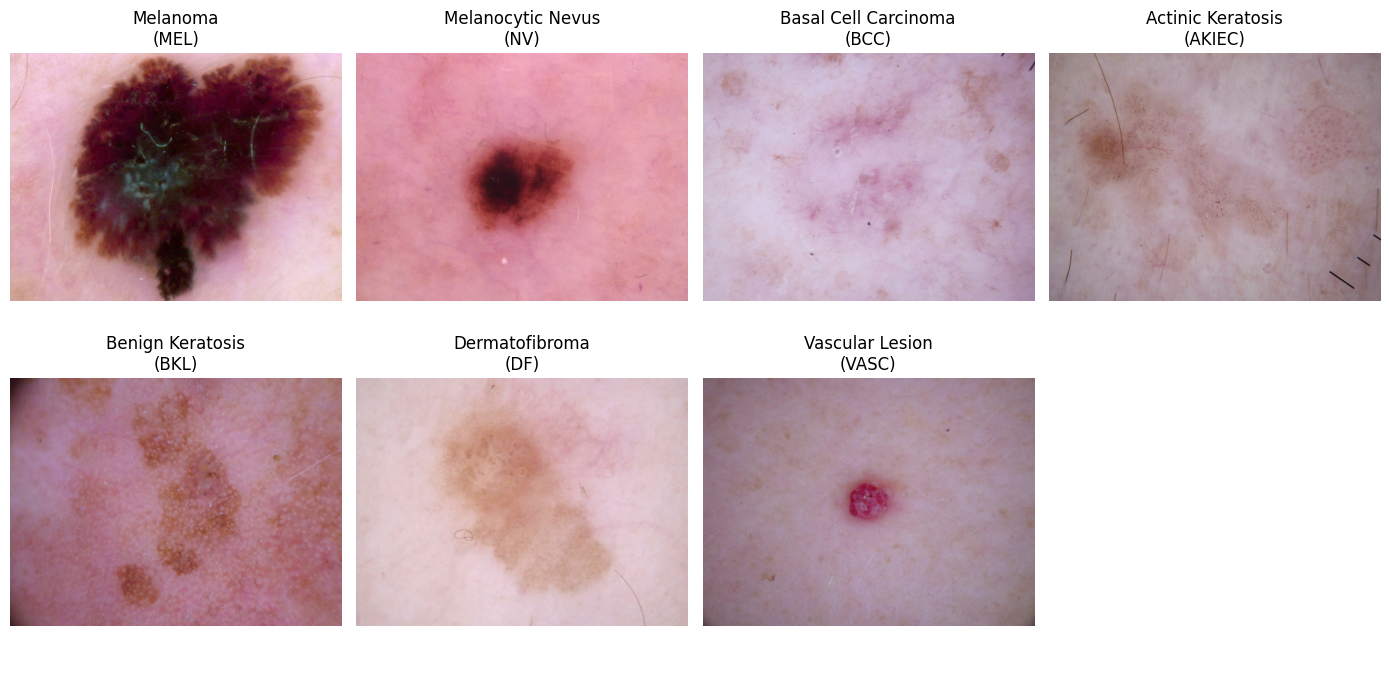

In [ ]:
# ============================================================
# STEP 6A — SAMPLE IMAGE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import os
import random

print("=" * 40)
print("STEP 6A — SAMPLE IMAGE VISUALIZATION")
print("=" * 40)


# ------------------------------------------------------------
# 1. Select One Image From Each Class
# ------------------------------------------------------------

sample_rows = []

for label in range(7):

    class_data = train_df[
        train_df["label"] == label
    ]

    sample_row = class_data.sample(
        n=1,
        random_state=SEED
    ).iloc[0]

    sample_rows.append(sample_row)


# ------------------------------------------------------------
# 2. Display Images
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)

axes = axes.flatten()


for i, row in enumerate(sample_rows):

    image_name = str(row["image"])

    image_path = os.path.join(
        IMAGE_DIR,
        image_name + ".jpg"
    )

    image = Image.open(
        image_path
    ).convert("RGB")

    axes[i].imshow(image)

    axes[i].set_title(
        f"{class_names[row['label']]}\n"
        f"({class_columns[row['label']]})"
    )

    axes[i].axis("off")


# Hide unused subplot
axes[7].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# STEP 7 — HYBRID CNN + ViT MODEL ARCHITECTURE
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

print("=" * 40)
print("STEP 7 — HYBRID CNN + ViT")
print("=" * 40)


# ------------------------------------------------------------
# 1. Number of Classes
# ------------------------------------------------------------

NUM_CLASSES = 7

print("\nNumber of Classes:", NUM_CLASSES)


# ------------------------------------------------------------
# 2. Load Pretrained ResNet18
# ------------------------------------------------------------

print("\nLoading ResNet18...")

resnet18 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Remove original classification layer
resnet18.fc = nn.Identity()

print("✓ ResNet18 loaded")
print("✓ Original FC layer removed")
print("✓ ResNet18 feature size: 512")


# ------------------------------------------------------------
# 3. Load Pretrained Vision Transformer
# ------------------------------------------------------------

print("\nLoading Vision Transformer...")

vit = models.vit_b_16(
    weights=models.ViT_B_16_Weights.DEFAULT
)

# Remove original classification head
vit.heads.head = nn.Identity()

print("✓ ViT loaded")
print("✓ Original classification head removed")
print("✓ ViT feature size: 768")


# ------------------------------------------------------------
# 4. Hybrid Model
# ------------------------------------------------------------

class HybridResNetViT(nn.Module):

    def __init__(
        self,
        resnet,
        vit,
        num_classes=7
    ):

        super().__init__()

        self.resnet = resnet
        self.vit = vit

        # Combined feature size
        fusion_dim = 512 + 768

        # Classification head
        self.classifier = nn.Sequential(

            nn.Linear(
                fusion_dim,
                512
            ),

            nn.ReLU(),

            nn.Dropout(
                p=0.30
            ),

            nn.Linear(
                512,
                num_classes
            )
        )


    def forward(self, x):

        # CNN features
        resnet_features = self.resnet(x)

        # ViT features
        vit_features = self.vit(x)

        # Feature fusion
        fused_features = torch.cat(
            [
                resnet_features,
                vit_features
            ],
            dim=1
        )

        # Final classification
        output = self.classifier(
            fused_features
        )

        return output


# ------------------------------------------------------------
# 5. Create Hybrid Model
# ------------------------------------------------------------

hybrid_model = HybridResNetViT(
    resnet=resnet18,
    vit=vit,
    num_classes=NUM_CLASSES
)


# ------------------------------------------------------------
# 6. Move Model to Device
# ------------------------------------------------------------

hybrid_model = hybrid_model.to(device)


# ------------------------------------------------------------
# 7. Model Summary
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("HYBRID MODEL ARCHITECTURE")
print("=" * 40)

print(hybrid_model)


# ------------------------------------------------------------
# 8. Test Forward Pass
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("FORWARD PASS TEST")
print("=" * 40)

hybrid_model.eval()

with torch.no_grad():

    test_images, test_labels = next(
        iter(val_loader)
    )

    test_images = test_images.to(device)

    outputs = hybrid_model(
        test_images
    )


print("\nInput Shape:")
print(test_images.shape)

print("\nOutput Shape:")
print(outputs.shape)

print("\nExpected Output Shape:")
print(
    f"[{test_images.shape[0]}, {NUM_CLASSES}]"
)


# ------------------------------------------------------------
# 9. Trainable Parameters
# ------------------------------------------------------------

trainable_parameters = sum(
    p.numel()
    for p in hybrid_model.parameters()
    if p.requires_grad
)

total_parameters = sum(
    p.numel()
    for p in hybrid_model.parameters()
)


print("\n" + "=" * 40)
print("PARAMETER INFORMATION")
print("=" * 40)

print(
    f"\nTotal Parameters      : "
    f"{total_parameters:,}"
)

print(
    f"Trainable Parameters  : "
    f"{trainable_parameters:,}"
)



STEP 7 — HYBRID CNN + ViT

Number of Classes: 7

Loading ResNet18...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 123MB/s] 


✓ ResNet18 loaded
✓ Original FC layer removed
✓ ResNet18 feature size: 512

Loading Vision Transformer...
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 230MB/s]  


✓ ViT loaded
✓ Original classification head removed
✓ ViT feature size: 768

HYBRID MODEL ARCHITECTURE
HybridResNetViT(
  (resnet): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 

In [ ]:
# ============================================================
# STEP 8 — TRAINING CONFIGURATION
# ============================================================

import torch
import torch.nn as nn

print("=" * 40)
print("STEP 8 — TRAINING CONFIGURATION")
print("=" * 40)


# ------------------------------------------------------------
# 1. Training Configuration
# ------------------------------------------------------------

NUM_CLASSES = 7

EPOCHS = 30

LEARNING_RATE = 1e-4

WEIGHT_DECAY = 1e-4

PATIENCE = 7


print("\nEpochs        :", EPOCHS)
print("Learning Rate :", LEARNING_RATE)
print("Weight Decay  :", WEIGHT_DECAY)
print("Early Stop    :", PATIENCE)


# ------------------------------------------------------------
# 2. Loss Function
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

print("\nLoss Function:")
print("✓ CrossEntropyLoss")


# ------------------------------------------------------------
# 3. Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    hybrid_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("\nOptimizer:")
print("✓ AdamW")


# ------------------------------------------------------------
# 4. Learning Rate Scheduler
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("\nScheduler:")
print("✓ ReduceLROnPlateau")
print("✓ Monitors Validation Macro F1")
print("✓ LR reduction factor: 0.5")


# ------------------------------------------------------------
# 5. Model Checkpoint
# ------------------------------------------------------------

BEST_MODEL_PATH = (
    "/kaggle/working/"
    "best_hybrid_cnn_vit.pth"
)

print("\nBest Model Path:")
print(BEST_MODEL_PATH)


# ------------------------------------------------------------
# 6. Training Strategy
# ------------------------------------------------------------

print("\n" + "=" * 40)
print("TRAINING STRATEGY")
print("=" * 40)

print("""
Training:
✓ WeightedRandomSampler
✓ Data augmentation
✓ AdamW optimizer

Validation:
✓ Natural distribution
✓ Used for model selection
✓ Macro F1 used as primary criterion

Test:
✓ Natural distribution
✓ Completely untouched
✓ Used only for final evaluation
""")


STEP 8 — TRAINING CONFIGURATION

Epochs        : 30
Learning Rate : 0.0001
Weight Decay  : 0.0001
Early Stop    : 7

Loss Function:
✓ CrossEntropyLoss

Optimizer:
✓ AdamW

Scheduler:
✓ ReduceLROnPlateau
✓ Monitors Validation Macro F1
✓ LR reduction factor: 0.5

Best Model Path:
/kaggle/working/best_hybrid_cnn_vit.pth

TRAINING STRATEGY

Training:
✓ WeightedRandomSampler
✓ Data augmentation
✓ AdamW optimizer

Validation:
✓ Natural distribution
✓ Used for model selection
✓ Macro F1 used as primary criterion

Test:
✓ Natural distribution
✓ Completely untouched
✓ Used only for final evaluation



In [ ]:
# STEP 9 — HYBRID CNN + ViT TRAINING

import time
import copy
import numpy as np
import torch
from sklearn.metrics import f1_score


print("STEP 9 — HYBRID CNN + ViT TRAINING")



# ------------------------------------------------------------
# 1. Training Variables
# ------------------------------------------------------------

best_val_f1 = 0.0
best_epoch = 0
patience_counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": [],
    "lr": []
}


# ------------------------------------------------------------
# 2. Training Loop
# ------------------------------------------------------------

for epoch in range(EPOCHS):

    start_time = time.time()

    # ========================================================
    # TRAINING
    # ========================================================

    hybrid_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = hybrid_model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            hybrid_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)


    train_loss = running_loss / total
    train_acc = correct / total


    # ========================================================
    # VALIDATION
    # ========================================================

    hybrid_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    val_predictions = []
    val_targets = []


    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = hybrid_model(images)

            loss = criterion(
                outputs,
                labels
            )

            val_running_loss += (
                loss.item() * images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_targets.extend(
                labels.cpu().numpy()
            )


    val_loss = (
        val_running_loss /
        val_total
    )

    val_acc = (
        val_correct /
        val_total
    )

    val_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )


    # ========================================================
    # LEARNING RATE SCHEDULER
    # ========================================================

    scheduler.step(val_f1)

    current_lr = optimizer.param_groups[0]["lr"]


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history["train_loss"].append(
        train_loss
    )

    history["train_acc"].append(
        train_acc
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_acc"].append(
        val_acc
    )

    history["val_f1"].append(
        val_f1
    )

    history["lr"].append(
        current_lr
    )


    # ========================================================
    # BEST MODEL
    # ========================================================

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        best_epoch = epoch + 1

        patience_counter = 0

        torch.save(
            hybrid_model.state_dict(),
            BEST_MODEL_PATH
        )

        best_marker = " ★ BEST"


    else:

        patience_counter += 1

        best_marker = ""


    # ========================================================
    # EPOCH RESULT
    # ========================================================

    epoch_time = time.time() - start_time

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"| Time: {epoch_time:.1f}s"
    )

    print(
        f"Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} "
        f"| Val Acc:   {val_acc:.4f}"
    )

    print(
        f"Val Macro F1: {val_f1:.4f} "
        f"| LR: {current_lr:.2e}"
        f"{best_marker}"
    )

    print("-" * 40)


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if patience_counter >= PATIENCE:

        print(
            f"\nEarly stopping triggered "
            f"after {epoch + 1} epochs."
        )

        break


# ------------------------------------------------------------
# 3. Load Best Model
# ------------------------------------------------------------

hybrid_model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)


STEP 9 — HYBRID CNN + ViT TRAINING
Epoch [01/30] | Time: 332.2s
Train Loss: 0.5676 | Train Acc: 0.7887
Val Loss:   0.6661 | Val Acc:   0.7390
Val Macro F1: 0.6626 | LR: 1.00e-04 ★ BEST
----------------------------------------
Epoch [02/30] | Time: 331.5s
Train Loss: 0.4417 | Train Acc: 0.8359
Val Loss:   0.6878 | Val Acc:   0.7603
Val Macro F1: 0.6631 | LR: 1.00e-04 ★ BEST
----------------------------------------
Epoch [03/30] | Time: 331.8s
Train Loss: 0.3835 | Train Acc: 0.8578
Val Loss:   0.6261 | Val Acc:   0.7403
Val Macro F1: 0.7218 | LR: 1.00e-04 ★ BEST
----------------------------------------
Epoch [04/30] | Time: 330.7s
Train Loss: 0.3261 | Train Acc: 0.8813
Val Loss:   0.7522 | Val Acc:   0.7217
Val Macro F1: 0.6347 | LR: 1.00e-04
----------------------------------------
Epoch [05/30] | Time: 331.5s
Train Loss: 0.3140 | Train Acc: 0.8837
Val Loss:   0.5875 | Val Acc:   0.7816
Val Macro F1: 0.7576 | LR: 1.00e-04 ★ BEST
----------------------------------------
Epoch [06/30] | T

<All keys matched successfully>

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import torch

print("\n" + "=" * 40)
print("STEP 10 — FINAL TEST EVALUATION")
print("=" * 40)

# --------------------------------------------------
# 1. Load BEST Hybrid model
# --------------------------------------------------

best_model_path = "/kaggle/working/best_hybrid_cnn_vit.pth"

checkpoint = torch.load(best_model_path, map_location=device)

# Handle both normal state_dict and checkpoint dictionary
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    hybrid_model.load_state_dict(checkpoint["model_state_dict"])
else:
    hybrid_model.load_state_dict(checkpoint)

hybrid_model = hybrid_model.to(device)
hybrid_model.eval()

print("Best model loaded successfully.")
print("Evaluating on untouched test set...")

# --------------------------------------------------
# 2. Test prediction
# --------------------------------------------------

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = hybrid_model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy
y_true = np.array(all_labels)
y_pred = np.array(all_predictions)
y_prob = np.array(all_probabilities)

# --------------------------------------------------
# 3. Calculate metrics
# --------------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

# Multiclass ROC-AUC
roc_auc = roc_auc_score(
    y_true,
    y_prob,
    multi_class="ovr",
    average="macro"
)

# --------------------------------------------------
# 4. Display final results
# --------------------------------------------------

print("\n" + "=" * 40)
print("FINAL TEST RESULTS")
print("=" * 40)

print(f"Accuracy          : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro Precision   : {precision:.4f} ({precision*100:.2f}%)")
print(f"Macro Recall      : {recall:.4f} ({recall*100:.2f}%)")
print(f"Macro F1-Score    : {f1:.4f} ({f1*100:.2f}%)")
print(f"Macro ROC-AUC     : {roc_auc:.4f} ({roc_auc*100:.2f}%)")


STEP 10 — FINAL TEST EVALUATION
Best model loaded successfully.
Evaluating on untouched test set...

FINAL TEST RESULTS
Accuracy          : 0.8762 (87.62%)
Macro Precision   : 0.8447 (84.47%)
Macro Recall      : 0.8459 (84.59%)
Macro F1-Score    : 0.8439 (84.39%)
Macro ROC-AUC     : 0.9760 (97.60%)


In [ ]:
print("\n" + "=" * 40)
print("SAVING BEST HYBRID MODEL")
print("=" * 40)

best_model_path = "/kaggle/working/best_hybrid_cnn_vit.pth"

# Save model weights
torch.save(hybrid_model.state_dict(), best_model_path)

print("Model saved successfully!")
print(f"Path: {best_model_path}")


SAVING BEST HYBRID MODEL
Model saved successfully!
Path: /kaggle/working/best_hybrid_cnn_vit.pth



CONFUSION MATRIX
[[120  39   1   1   6   0   0]
 [ 44 929   9   3  21   0   0]
 [  2   0  71   2   2   0   0]
 [  0   0   6  37   6   0   0]
 [ 15  16   3   7 124   0   0]
 [  0   1   0   0   0  16   0]
 [  0   2   0   0   0   0  20]]


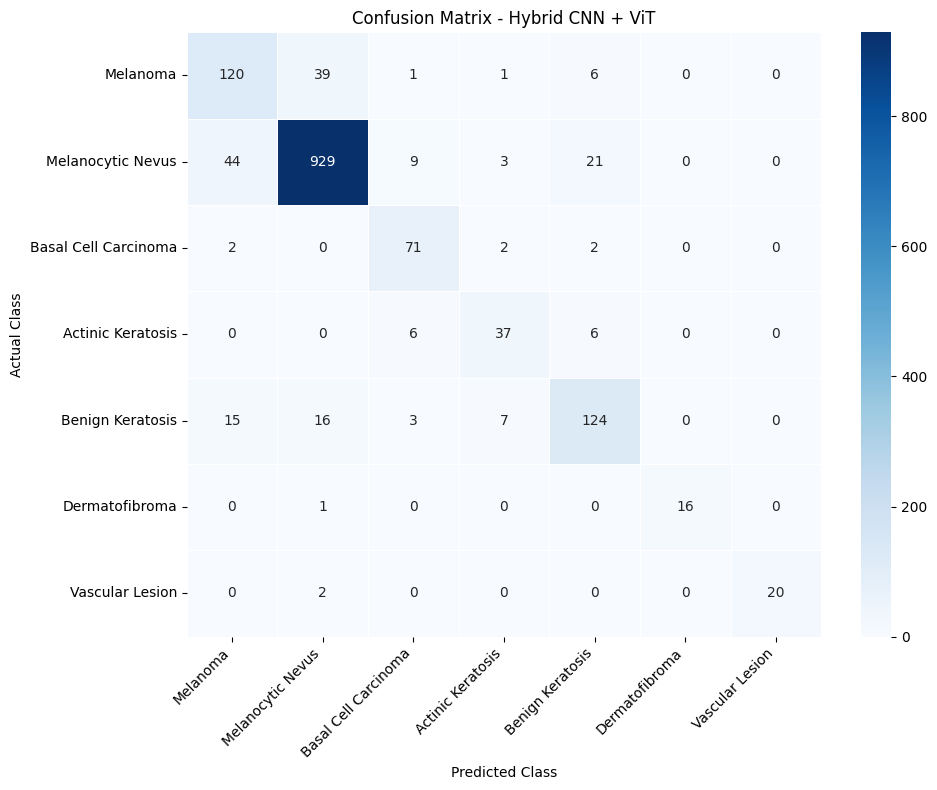

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("\n" + "=" * 40)
print("CONFUSION MATRIX")
print("=" * 40)

# Class names
class_names = [
    "Melanoma",
    "Melanocytic Nevus",
    "Basal Cell Carcinoma",
    "Actinic Keratosis",
    "Benign Keratosis",
    "Dermatofibroma",
    "Vascular Lesion"
]

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display numerical matrix
print(cm)

# Plot
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5
)

plt.title("Confusion Matrix - Hybrid CNN + ViT")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()